In [1]:
# import libraries 
import time
import re
import datetime
import csv
import logging
import sys
import os
import random

from selenium import webdriver
from bs4 import BeautifulSoup

# cần 2 cái dưới để điều hướng con trỏ chuột sang trang kế
from selenium.webdriver.common.by import By
from selenium.common.exceptions import NoSuchElementException, ElementClickInterceptedException
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

import logging # dùng để ghi tiến trình & lỗi khi crawl data

# Import 3 vũ khí mới để vượt qua bước Login của web
import os # để đọc thông tin trong file `.env`
import undetected_chromedriver as uc
from dotenv import load_dotenv

In [2]:
# --- Thiết lập logging ---
logging.basicConfig(
    filename="logging_topcv.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    encoding='utf-8'
)

# 1. Truy cập web

In [3]:
# https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=2

KEYWORDS = ["Data Analyst"] # Rút gọn để test
BASE_URL_TEMPLATE = "https://www.topcv.vn/tim-viec-lam-{keyword}?sort=new&type_keyword=1&page={page}"
MAX_PAGES = 3
OUTPUT_CSV = "data_topcv.csv"

# ── 3. LOGGING (Giữ nguyên của bạn) ──────────────────────────────────────────────
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(message)s")

In [4]:
# THAY ĐỔI 1: Dùng undetected_chromedriver thay vì webdriver.Chrome()
options = uc.ChromeOptions()


# Thêm cấu hình vô hiệu hóa chức năng hỏi lưu mật khẩu VÀ chặn thông báo (Notifications)
prefs = {
    "credentials_enable_service": False,
    "profile.password_manager_enabled": False,
    "profile.default_content_setting_values.notifications": 2  # Thêm dòng này! 2 có nghĩa là Block

}
options.add_experimental_option("prefs", prefs)



# THÊM version_main=140 VÀO ĐÂY vì nó mặc định chạy ver Chrome 147
driver = uc.Chrome(options=options, version_main=140) 


# Thay vì maximize_window(), dùng set_window_size và set_window_position
# Đặt kích thước cho trình duyệt (chiều rộng x chiều cao)
driver.set_window_size(900, 1080) # Bạn có thể thay đổi số theo độ phân giải màn hình
# (Tùy chọn) Đặt vị trí xuất hiện của cửa sổ (x, y) trên màn hình (0,0 là góc trên cùng bên trái)
driver.set_window_position(900, 0) # Có thể đẩy nó sang lề phải của màn hình

{'height': 882, 'width': 903, 'x': 900, 'y': 0}

# 2. Lấy link job trong 1 page

In [22]:
# Mở trang TopCV (trang 1)
url = 'https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1'
driver.get(url)
time.sleep(random.uniform(3, 6)) # Đợi 3 giây để trang web tải hoàn toàn

In [23]:
# Cuộn xuống để load toàn bộ job
last_height = driver.execute_script("return document.body.scrollHeight")
while True:
    driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
    time.sleep(3)
    new_height = driver.execute_script("return document.body.scrollHeight")
    if new_height == last_height:
        break
    last_height = new_height

In [24]:
# Lấy mã nguồn HTML của trang web
html = driver.page_source
soup = BeautifulSoup(html, 'html.parser')

In [10]:
soup

<html lang="vi"><head>
<meta charset="utf-8"/>
<meta content="IE=edge,chrome=1" http-equiv="X-UA-Compatible"/>
<meta content="width=device-width, initial-scale=1.0, maximum-scale=1" name="viewport"/>
<link href="https://static.topcv.vn/v4/image/favicon.ico" rel="icon" type="image/x-icon"/>
<meta content="1478418029113221" property="fb:app_id"/>
<meta content="9Rx6GhUdNITi309kvAU7SImxemxYolbAzIMofhZH" name="csrf-token"/>
<meta content="okX9WYRRKSr_EuYuN-C58UPMnAAusti-V-UFcpJEVZg" name="google-site-verification"/>
<meta content="UTd2SHpqb1hYdC9mUnV4YUFDN3U0QT090" name="dmca-site-verification"/>
<link href="https://www.googletagmanager.com" rel="preconnect"/>
<link href="https://analytics.tiktok.com" rel="preconnect"/>
<link href="https://www.googleadservices.com" rel="preconnect"/>
<link href="https://www.google-analytics.com" rel="preconnect"/>
<link href="https://connect.facebook.net" rel="preconnect"/>
<link href="https://www.gstatic.com" rel="preconnect"/>
<link href="https://www.top

In [25]:
# 1. Tìm container chứa danh sách công việc BẰNG "jobList" (Dùng find)
job_list_box = soup.find("div", class_ = "job-list-search-result")
job_list_box

<div class="job-list-search-result">
<div class="job-item-search-result bg-highlight job-ta" data-box="BoxSearchResult" data-job-id="2121762" data-job-position="1" data-u-sr-id="pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671">
<div class="avatar">
<a aria-label="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu" href="https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html?ta_source=JobSearchList_LinkDetail&amp;u_sr_id=pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671" rel="nooppener noreferrer" target="_blank">
<img alt="Viện Nghiên cứu Quản Lý Hành Chính" class="w-100 lazy" data-src="https://cdn-new.topcv.vn/unsafe/150x/https://static.topcv.vn/company_logos/2eFjtXRhCQqYF50vKzBM52ROEnF8lupz_1775464996____dd25ff9a8f2fe03194a9b7e593b11f2a.png" title="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu"/>
</a>
</div>
<div class="body">
<div class="body-box">
<div class="body-content">
<div class="title-block">
<div>
<h3 class="title">
<div class="box-label-t

In [ ]:
a_tags = job_list_box.select('h3.title a[href]')
a_tags

[<a href="https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html?ta_source=JobSearchList_LinkDetail&amp;u_sr_id=HKJJN0HvWXvPduHJqqca4Kfo0BWvYPjxR94HoGSi_1775749305" rel="nooppener noreferrer" target="_blank">
 <span data-container="body" data-original-title="Chuyên Viên Phân Tích Dữ Liệu &amp; AI Agent" data-placement="top" data-toggle="tooltip" title="">Chuyên Viên Phân Tích Dữ Liệu &amp; AI Agent</span>
 <span class="icon-verified-employer level-five">
 <i class="fa-solid fa-circle-check icon-verified-employer-tooltip" data-container="body" data-html="true" data-original-title="
   &lt;b&gt;Nhà tuyển dụng&lt;/b&gt;&lt;span&gt; đã được xác thực:&lt;/span&gt;&lt;br&gt;
   &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực email tên miền công ty&lt;/span&gt;&lt;br&gt;
   &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực số điện thoại&lt;/span&gt;&lt;br&gt;
   &lt;span&gt;&lt;i class='

In [17]:
raw_link = a_tags[0].get('href')
raw_link

'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html?ta_source=JobSearchList_LinkDetail&u_sr_id=HKJJN0HvWXvPduHJqqca4Kfo0BWvYPjxR94HoGSi_1775749305'

In [18]:
clean_link = raw_link.split('?')[0]
clean_link

'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html'

In [8]:
def get_links(soup):
    all_links = []
    try:
        # 1. Tìm khung chứa toàn bộ list job (Mỏ neo lớn)
        # Dùng lambda để bắt class chính xác dù có khoảng trắng thừa
        job_list_box = soup.find("div", class_ = "job-list-search-result")
        
        if job_list_box:
            # 2. Tìm tất cả các thẻ <a> chứa link job. 
            # Trong TopCV, link job nằm ở thẻ <a> bọc cái ảnh (avatar) HOẶC thẻ <a> bọc cái Tiêu đề (h3.title).
            # Ở đây ta lấy thẻ <a> nằm trong <h3 class="title"> cho chuẩn nhất.
            a_tags = job_list_box.select('h3.title a[href]')
            
            for a in a_tags:
                raw_link = a.get('href')
                
                if raw_link:
                    # 3. LÀM SẠCH LINK: Cắt chuỗi tại dấu '?' và chỉ lấy phần đầu tiên (index 0)
                    # Ví dụ: ".../2106718.html?ta_source=..." -> ".../2106718.html"
                    clean_link = raw_link.split('?')[0]
                    all_links.append(clean_link)
                    
    except Exception as e:
        logging.error(f"Lỗi khi lấy danh sách link: {e}")
        pass
        
    return all_links

In [9]:
# 1 trang sẽ MAX 50 JOB

job_links = get_links(soup)
job_links

['https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html',
 'https://www.topcv.vn/viec-lam/integration-specialist-night-shift-e-com-erp-data/2105797.html',
 'https://www.topcv.vn/viec-lam/nhan-vien-quan-tri-du-lieu-data-admin/1220636.html',
 'https://www.topcv.vn/viec-lam/thuc-tap-sinh-tai-nang-tech-data-risk-business/2103006.html',
 'https://www.topcv.vn/viec-lam/data-engineer-data-analytics-de-da/2101649.html',
 'https://www.topcv.vn/viec-lam/nhan-su-phan-tich-du-lieu-va-bao-cao-it06/2100089.html',
 'https://www.topcv.vn/viec-lam/nhan-vien-data-phan-tich-du-

# 3. Con trỏ chuột sang trang kế tiếp
Output test với **`KEYWORD`** = `data analyst` là lấy đc 115 job từ 3 page

In [29]:
KEYWORD = "data analyst"
MAX_PAGES = 5 # Đặt số trang tối đa bạn muốn cào
all_job_links = [] # List tổng chứa tất cả các link thu thập được từ mọi trang

print(f"\n{'='*50}")
print(f"BẮT ĐẦU CÀO DANH SÁCH LINK CHO TỪ KHÓA: {KEYWORD.upper()}")
print(f"{'='*50}")


BẮT ĐẦU CÀO DANH SÁCH LINK CHO TỪ KHÓA: DATA ANALYST


In [16]:
paginate_span = soup.find('span', id='job-listing-paginate-text')
if paginate_span:
    # Lấy toàn bộ text (ví dụ: "1 / 3 trang")
    text = paginate_span.get_text(strip=True)

text

'1/\xa03 trang'

In [17]:
# Dùng Regex để tìm tất cả các con số trong chuỗi
# match_numbers sẽ là một list: ['1', '3']
match_numbers = re.findall(r'\d+', text)
match_numbers

['1', '3']

In [18]:
if len(match_numbers) >= 2:
    # Con số thứ 2 chính là tổng số trang
    total_pages = int(match_numbers[1])
    
total_pages

3

## 3.2 test vs số trang có 2 chữ số

In [19]:
# Mở trang TopCV (trang 1)
url = 'https://www.topcv.vn/tim-viec-lam-data?sort=new&type_keyword=1&page=1'
driver.get(url)
time.sleep(random.uniform(3, 6)) # Đợi 3 giây để trang web tải hoàn toàn


# Cuộn xuống để load toàn bộ job
last_height = driver.execute_script("return document.body.scrollHeight")
while True:
    driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
    time.sleep(3)
    new_height = driver.execute_script("return document.body.scrollHeight")
    if new_height == last_height:
        break
    last_height = new_height


# Lấy mã nguồn HTML của trang web
html_test = driver.page_source
soup_test = BeautifulSoup(html_test, 'html.parser')


# ____________________________________________________


paginate_span = soup_test.find('span', id='job-listing-paginate-text')
if paginate_span:
    # Lấy toàn bộ text (ví dụ: "1 / 3 trang")
    text = paginate_span.get_text(strip=True)


# Dùng Regex để tìm tất cả các con số trong chuỗi
# match_numbers sẽ là một list: ['1', '3']
match_numbers = re.findall(r'\d+', text)



if len(match_numbers) >= 2:
    # Con số thứ 2 chính là tổng số trang
    total_pages = int(match_numbers[1])
    
total_pages

11

In [20]:
match_numbers

['1', '11']

## 3.3 Tiếp tục code hàm

In [30]:
formatted_keyword = KEYWORD.lower().replace(' ', '-')

formatted_keyword

'data-analyst'

In [24]:
KEYWORD

'data-analyst'

In [26]:
KEYWORD.lower()

'data-analyst'

In [32]:
# https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1
# Khi chỉnh thủ công page = 4 OR 5 thì, web tự động về page = 3


def get_total_pages(soup):
    """Hàm lấy tổng số trang từ HTML của TopCV"""
    try:
        # Tìm thẻ span chứa text phân trang
        paginate_span = soup.find('span', id='job-listing-paginate-text')
        if paginate_span:
            # Lấy toàn bộ text (ví dụ: "1 / 3 trang")
            text = paginate_span.get_text(strip=True)
            
            # Dùng Regex để tìm tất cả các con số trong chuỗi
            # match_numbers sẽ là một list: ['1', '3']
            match_numbers = re.findall(r'\d+', text)
            
            if len(match_numbers) >= 2:
                # Con số thứ 2 chính là tổng số trang
                total_pages = int(match_numbers[1])
                return total_pages
                
        # Nếu chỉ có 1 trang, TopCV thường không hiện thanh phân trang
        return 1 
    except Exception as e:
        logging.error(f"Lỗi khi lấy tổng số trang: {e}")
        return 1 # Mặc định là 1 nếu có lỗi

# ==========================================
# VÒNG LẶP CHÍNH (Trong hàm main của bạn)
# ==========================================

raw_keyword = KEYWORD

# ... (Khởi tạo driver, đăng nhập...) ...
formatted_keyword = raw_keyword.lower().replace(' ', '-')
print(f"\n{'='*60}")
print(f"BẮT ĐẦU QUÉT KEYWORD: {raw_keyword.upper()}")

# 1. Truy cập trang 1 ĐẦU TIÊN để lấy tổng số trang
first_page_url = f"https://www.topcv.vn/tim-viec-lam-{formatted_keyword}?sort=new&type_keyword=1&page=1"
driver.get(first_page_url)
time.sleep(3)

# Lấy HTML của trang 1
soup_page_1 = BeautifulSoup(driver.page_source, 'html.parser')

# 2. Gọi hàm lấy tổng số trang thực tế
actual_total_pages = get_total_pages(soup_page_1)
print(f"[*] Từ khóa '{raw_keyword}' có tổng cộng {actual_total_pages} trang.")

# 3. So sánh với MAX_PAGES của bạn
# Nếu số trang thực tế ít hơn MAX_PAGES, ta chỉ cào đến số trang thực tế
# Nếu số trang thực tế nhiều hơn MAX_PAGES, ta cào đến MAX_PAGES
pages_to_crawl = min(actual_total_pages, MAX_PAGES)
print(f"[*] Sẽ tiến hành cào {pages_to_crawl} trang.")


BẮT ĐẦU QUÉT KEYWORD: DATA ANALYST
[*] Từ khóa 'data analyst' có tổng cộng 3 trang.
[*] Sẽ tiến hành cào 3 trang.


In [34]:
# https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1
# Vòng lặp chạy từ trang 1 đến MAX_PAGES OR actual_total_pages


for page in range(1, pages_to_crawl + 1):
    # 1. Tạo URL cho trang hiện tại
    url = f'https://www.topcv.vn/tim-viec-lam-{formatted_keyword}?sort=new&type_keyword=1&page={page}'
    print(f"\n---> Đang truy cập Trang {page}: {url}")
    
    driver.get(url)
    time.sleep(3) # Đợi trang load cơ bản


---> Đang truy cập Trang 1: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1

---> Đang truy cập Trang 2: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=2

---> Đang truy cập Trang 3: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=3


In [35]:
def get_links(soup):
    try:
        # 1. Tìm khung chứa toàn bộ list job (Mỏ neo lớn)
        # Dùng lambda để bắt class chính xác dù có khoảng trắng thừa
        job_list_box = soup.find("div", class_ = "job-list-search-result")
        
        if job_list_box:
            # 2. Tìm tất cả các thẻ <a> chứa link job. 
            # Trong TopCV, link job nằm ở thẻ <a> bọc cái ảnh (avatar) HOẶC thẻ <a> bọc cái Tiêu đề (h3.title).
            # Ở đây ta lấy thẻ <a> nằm trong <h3 class="title"> cho chuẩn nhất.
            a_tags = job_list_box.select('h3.title a[href]')
            
            for a in a_tags:
                raw_link = a.get('href')
                
                if raw_link:
                    # 3. LÀM SẠCH LINK: Cắt chuỗi tại dấu '?' và chỉ lấy phần đầu tiên (index 0)
                    # Ví dụ: ".../2106718.html?ta_source=..." -> ".../2106718.html"
                    clean_link = raw_link.split('?')[0]
                    all_job_links.append(clean_link)
                    
    except Exception as e:
        logging.error(f"Lỗi khi lấy danh sách link: {e}")
        pass
        
    return all_job_links





# https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1


# 1. Vòng lặp chạy từ trang 1 đến MAX_PAGES OR actual_total_pages
for page in range(1, pages_to_crawl + 1):
    # 1. Tạo URL cho trang hiện tại
    url = f'https://www.topcv.vn/tim-viec-lam-{formatted_keyword}?sort=new&type_keyword=1&page={page}'
    print(f"\n---> Đang truy cập Trang {page}: {url}")
    
    driver.get(url)
    time.sleep(random.uniform(3, 6)) # Đợi 3 giây để trang web tải hoàn toàn


    # 2. Cuộn xuống cuối trang để load toàn bộ job (Lazy load)
    last_height = driver.execute_script("return document.body.scrollHeight")
    while True:
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(2)
        new_height = driver.execute_script("return document.body.scrollHeight")
        if new_height == last_height:
            break
        last_height = new_height


    # 3. Lấy mã nguồn HTML đưa cho BeautifulSoup
    html = driver.page_source
    soup = BeautifulSoup(html, 'html.parser')

    get_links(soup)


all_job_links


---> Đang truy cập Trang 1: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=1

---> Đang truy cập Trang 2: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=2

---> Đang truy cập Trang 3: https://www.topcv.vn/tim-viec-lam-data-analyst?sort=new&type_keyword=1&page=3


['https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html',
 'https://www.topcv.vn/viec-lam/integration-specialist-night-shift-e-com-erp-data/2105797.html',
 'https://www.topcv.vn/viec-lam/nhan-vien-quan-tri-du-lieu-data-admin/1220636.html',
 'https://www.topcv.vn/viec-lam/data-engineer-data-analytics-de-da/2101649.html',
 'https://www.topcv.vn/viec-lam/thuc-tap-sinh-tai-nang-tech-data-risk-business/2103006.html',
 'https://www.topcv.vn/viec-lam/nhan-su-phan-tich-du-lieu-va-bao-cao-it06/2100089.html',
 'https://www.topcv.vn/viec-lam/nhan-vien-data-phan-tich-du-

# 4. Bắt đầu lấy data sản phẩm nè

1.	`job_url`: Link chi tiết của job đó.
2.	`job_title`: Tiêu đề công việc.

3.	`salary`: Mức lương (thỏa thuận OR rank min - max).
4.	`location`: Địa điểm làm việc.
5.	`years_experience`: kinh nghiệm

6.	`job_deadline`: (Hạn nộp hồ sơ)
7.	`date_post`: Tính từ ngày dealine trừ đi 1 tháng

8.	`company_name`: Tên công ty.
9.	`company_industry`: Lĩnh vực cty (Dược phẩm / Y tế / Công nghệ sinh học)

10.	`level`: cấp bậc (Nhân viên)
11.	`education_level`: (Trình độ học vấn) (cao đẳng trở lên)
12.	`hire_number`: Số lượng tuyển
13.	`job_type`: Hình thức làm việc

14.	`expertise`: Chuyên môn (Data Analyst Chăm sóc sức khỏe / Làm đẹp Y tế / Dược phẩm)

15.	`job_description`: Mô tả công việc.
16.	`requirements`: Yêu cầu công việc (Kinh nghiệm, kỹ năng).
17.	`benefits`: Phúc lợi (Lý do tại sao bạn sẽ yêu thích làm việc tại đây).



16. `date_post`
```py
Về date_post (Ngày đăng). Có lẽ t sẽ cào nó bên ngoài, vì nó chỉ ở bên ngoài
1. lấy list link trong 1 page đính kèm date post ( NOW - số ngày đã up)
2. Check duplicate link
3. Đi vào crawl chi tiết list link
4. Next trang tiếp theo
```

In [5]:
# https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html

job_link = 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html'
job_link = job_link.split('?')[0]
job_link

'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html'

In [6]:

# Mở trang job chi tiết
driver.get(job_link)
time.sleep(random.uniform(3, 6)) # Đợi 3 giây để trang web tải hoàn toàn

# Cuộn xuống để load toàn bộ job
last_height = driver.execute_script("return document.body.scrollHeight")
while True:
    driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
    time.sleep(3)
    new_height = driver.execute_script("return document.body.scrollHeight")
    if new_height == last_height:
        break
    last_height = new_height

In [7]:
# Lấy mã nguồn HTML của trang web
new_html = driver.page_source
new_soup = BeautifulSoup(new_html, 'html.parser')

<html lang="vi"><head>
<meta charset="utf-8"/>
<meta content="IE=edge,chrome=1" http-equiv="X-UA-Compatible"/>
<meta content="width=device-width, initial-scale=1.0, maximum-scale=1" name="viewport"/>
<link href="https://static.topcv.vn/v4/image/favicon.ico" rel="icon" type="image/x-icon"/>
<meta content="1478418029113221" property="fb:app_id"/>
<meta content="PNQXugwZLWo53pooaSdzJHtOyFCPrw5TUdyk5rkc" name="csrf-token"/>
<meta content="okX9WYRRKSr_EuYuN-C58UPMnAAusti-V-UFcpJEVZg" name="google-site-verification"/>
<meta content="UTd2SHpqb1hYdC9mUnV4YUFDN3U0QT090" name="dmca-site-verification"/>
<link href="https://www.googletagmanager.com" rel="preconnect"/>
<link href="https://analytics.tiktok.com" rel="preconnect"/>
<link href="https://www.googleadservices.com" rel="preconnect"/>
<link href="https://www.google-analytics.com" rel="preconnect"/>
<link href="https://connect.facebook.net" rel="preconnect"/>
<link href="https://www.gstatic.com" rel="preconnect"/>
<link href="https://www.top
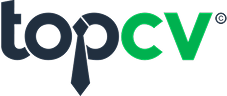

In [10]:
new_soup

## 4.1 Trường hợp các link job bình thường
- Link job ko chứa text "https://www.topcv.vn/brand/"

### 4.1.1	Title Job

In [10]:
# 1. Tìm khối chứa thông tin header (Mỏ neo bền vững)
header_box = new_soup.find('div', id='header-job-info')
header_box

<div class="job-detail__box--left job-detail__info" id="header-job-info">
<h1 class="job-detail__info--title">
<a class="text-highlight" href="https://www.topcv.vn/tim-viec-lam-chuyen-vien-phan-tich-du-lieu" target="_blank" title="Việc làm Chuyên Viên Phân Tích Dữ Liệu">Chuyên Viên Phân Tích Dữ Liệu</a> &amp; AI Agent
        <span class="icon-verified-employer level-five">
<i class="fa-solid fa-circle-check icon-verified-employer-tooltip" data-container="body" data-html="true" data-original-title="
  &lt;b&gt;Nhà tuyển dụng&lt;/b&gt;&lt;span&gt; đã được xác thực:&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực email tên miền công ty&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực số điện thoại&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã được duyệt Giấy phép kinh doanh&lt;/span&gt;&lt;br&gt;
  &l

In [14]:
title_tag = header_box.find('h1')
title_tag

<h1 class="job-detail__info--title">
<a class="text-highlight" href="https://www.topcv.vn/tim-viec-lam-chuyen-vien-phan-tich-du-lieu" target="_blank" title="Việc làm Chuyên Viên Phân Tích Dữ Liệu">Chuyên Viên Phân Tích Dữ Liệu</a> &amp; AI Agent
        <span class="icon-verified-employer level-five">
<i class="fa-solid fa-circle-check icon-verified-employer-tooltip" data-container="body" data-html="true" data-original-title="
  &lt;b&gt;Nhà tuyển dụng&lt;/b&gt;&lt;span&gt; đã được xác thực:&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực email tên miền công ty&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã xác thực số điện thoại&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt; Đã được duyệt Giấy phép kinh doanh&lt;/span&gt;&lt;br&gt;
  &lt;span&gt;&lt;i class='fa-solid fa-circle-check color-green'&gt;&lt;/i&gt;

In [12]:
title_tag.get_text(separator=' ', strip=True)

'Chuyên Viên Phân Tích Dữ Liệu & AI Agent'

In [8]:
# function 1: lấy tiêu đề job

def get_title(soup):
    try:
        # 1. Tìm cái hộp chứa thông tin (Mỏ neo lớn nhất, dùng ID là an toàn tuyệt đối)
        header_box = soup.find('div', id='header-job-info')
        
        if header_box:
            # 2. Tìm thẻ <h1> duy nhất bên trong cái hộp đó
            # Không cần quan tâm class của nó là gì
            title_tag = header_box.find('h1')
            
            if title_tag:
                # 3. Lấy text và làm sạch
                # Lưu ý: Thẻ h1 này có chứa một cái icon (thẻ span class="icon-verified-employer")
                # Nếu bạn dùng get_text() bình thường, nó có thể lôi cả text ẩn trong icon ra.
                # Để an toàn, ta chỉ lấy text của thẻ <a> và các text node trực tiếp của <h1>
                
                # Cách an toàn nhất: Lấy toàn bộ text, sau đó xóa các khoảng trắng thừa
                raw_title = title_tag.get_text(separator=' ', strip=True)
                
                # (Tùy chọn) Nếu cái icon có chứa text rác, bạn có thể xóa thẻ span đó đi trước khi lấy text
                # icon_span = title_tag.find('span', class_='icon-verified-employer')
                # if icon_span:
                #     icon_span.decompose() # Xóa thẻ span khỏi cây HTML
                # return title_tag.get_text(strip=True)
                
                return raw_title
                
        return None
    except Exception as e:
        logging.error(f"Lỗi khi lấy title: {e}")
        return None

In [9]:
# test function: lấy tiêu đề job
title = get_title(new_soup)
title

'Chuyên Viên Phân Tích Dữ Liệu & AI Agent'

### 4.1.2	Salary

In [18]:
# Tìm khối chứa lương
salary_box = header_box.find('div', class_='section-salary')
salary_box

<div class="job-detail__info--section section-salary">
<div class="job-detail__info--section-icon">
<svg fill="none" height="24" viewbox="0 0 24 24" width="24" xmlns="http://www.w3.org/2000/svg">
<path d="M21.92 16.75C21.59 19.41 19.41 21.59 16.75 21.92C15.14 22.12 13.64 21.68 12.47 20.82C11.8 20.33 11.96 19.29 12.76 19.05C15.77 18.14 18.14 15.76 19.06 12.75C19.3 11.96 20.34 11.8 20.83 12.46C21.68 13.64 22.12 15.14 21.92 16.75Z" fill="white"></path>
<path d="M9.99 2C5.58 2 2 5.58 2 9.99C2 14.4 5.58 17.98 9.99 17.98C14.4 17.98 17.98 14.4 17.98 9.99C17.97 5.58 14.4 2 9.99 2ZM9.05 8.87L11.46 9.71C12.33 10.02 12.75 10.63 12.75 11.57C12.75 12.65 11.89 13.54 10.84 13.54H10.75V13.59C10.75 14 10.41 14.34 10 14.34C9.59 14.34 9.25 14 9.25 13.59V13.53C8.14 13.48 7.25 12.55 7.25 11.39C7.25 10.98 7.59 10.64 8 10.64C8.41 10.64 8.75 10.98 8.75 11.39C8.75 11.75 9.01 12.04 9.33 12.04H10.83C11.06 12.04 11.24 11.83 11.24 11.57C11.24 11.22 11.18 11.2 10.95 11.12L8.54 10.28C7.68 9.98 7.25 9.37 7.25 8.42C7.

In [ ]:
# Lấy giá trị bên trong
# value_tag = salary_box.find('div', class_='job-detail__info--section-content-value')

pattern_value_tag = re.compile(r'(?=.*job-detail)(?=.*info)(?=.*section-content-value)', re.IGNORECASE)
value_tag = location_box.find('div', class_=pattern_value_tag)
value_tag

<div class="job-detail__info--section-content-value">Thoả thuận</div>

In [20]:
salary = value_tag.get_text(strip=True)
salary

'Thoả thuận'

In [ ]:
# function 2:lấy mức lương

def get_salary(soup):
    try:
        header_box = soup.find('div', id='header-job-info')
        if header_box:
            # Tìm khối chứa lương
            salary_box = header_box.find('div', class_='section-salary')
            if salary_box:
                # Lấy giá trị bên trong
                value_tag = salary_box.find('div', class_='job-detail__info--section-content-value')
                if value_tag:
                    return value_tag.get_text(strip=True)
        return None
    except Exception:
        return None

In [23]:
salary = get_salary(new_soup)
salary

'Thoả thuận'

### 4.1.3       location

In [24]:
# Tìm khối chứa địa điểm
location_box = header_box.find('div', class_='section-location')
location_box

<div class="job-detail__info--section section-location">
<div class="job-detail__info--section-icon">
<svg fill="none" height="24" viewbox="0 0 25 24" width="25" xmlns="http://www.w3.org/2000/svg">
<path d="M21.2866 8.45C20.2366 3.83 16.2066 1.75 12.6666 1.75C12.6666 1.75 12.6666 1.75 12.6566 1.75C9.1266 1.75 5.0866 3.82 4.0366 8.44C2.8666 13.6 6.0266 17.97 8.8866 20.72C9.9466 21.74 11.3066 22.25 12.6666 22.25C14.0266 22.25 15.3866 21.74 16.4366 20.72C19.2966 17.97 22.4566 13.61 21.2866 8.45ZM12.6666 13.46C10.9266 13.46 9.5166 12.05 9.5166 10.31C9.5166 8.57 10.9266 7.16 12.6666 7.16C14.4066 7.16 15.8166 8.57 15.8166 10.31C15.8166 12.05 14.4066 13.46 12.6666 13.46Z" fill="white"></path>
</svg>
</div>
<div class="job-detail__info--section-content">
<div class="job-detail__info--section-content-title">Địa điểm</div>
<div class="job-detail__info--section-content-value"><span class="text-highlight" data-html="true" data-original-title="
            &lt;div style='text-align: left; display: 

In [ ]:
# Cái này chứa cả html của icon địa điểm và text Location

value_tag = location_box.find('div', class_='job-detail__info--section-content-value')
value_tag

<div class="job-detail__info--section-content-value"><span class="text-highlight" data-html="true" data-original-title="
            &lt;div style='text-align: left; display: flex; flex-direction: column;'&gt;
                &lt;p style='color: #4FF398; margin: 0 0 4px 0; font-weight: 400; font-size: 12px; line-height: 18px; letter-spacing: 0.12px;'&gt;
                    Địa điểm làm việc đã được cập nhật theo Danh mục Hành chính mới (thêm quận/huyện cũ tương ứng để dễ dàng tra cứu)
                &lt;/p&gt;
                &lt;ul style='margin: 0; padding-left: 24px; font-weight: 400; font-size: 12px; line-height: 18px; letter-spacing: 0.12px; text-align: left;'&gt;
                    &lt;li&gt;&lt;li&gt;Hồ Chí Minh (mới): Quận 3&lt;/li&gt;&lt;/li&gt;
                &lt;/ul&gt;
            &lt;/div&gt;
        " data-placement="top" data-toggle="tooltip"><a href="https://www.topcv.vn/tim-viec-lam-chuyen-vien-phan-tich-du-lieu-tai-ho-chi-minh-kl2" target="_blank" title="Việc làm 

In [ ]:
# Lấy giá trị Location
value_tag.get_text(strip=True)

'Hồ Chí Minh'

In [27]:
# function 3: lấy địa điểm việc làm

def get_location(soup):
    try:
        header_box = soup.find('div', id='header-job-info')
        if header_box:
            # Tìm khối chứa địa điểm
            location_box = header_box.find('div', class_='section-location')
            if location_box:
                value_tag = location_box.find('div', class_='job-detail__info--section-content-value')
                if value_tag:
                    return value_tag.get_text(strip=True)
        return None
    except Exception:
        return None

In [28]:
location = get_location(new_soup)
location

'Hồ Chí Minh'

### 4.1.4       years_experience

In [ ]:
# Tìm khối chứa kinh nghiệm
exp_box = header_box.find('div', class_='section-experience')
exp_box

<div class="job-detail__info--section section-experience" id="job-detail-info-experience">
<div class="job-detail__info--section-icon">
<svg fill="none" height="24" viewbox="0 0 24 24" width="24" xmlns="http://www.w3.org/2000/svg">
<path d="M17.39 15.67L13.35 12H10.64L6.59998 15.67C5.46998 16.69 5.09998 18.26 5.64998 19.68C6.19998 21.09 7.53998 22 9.04998 22H14.94C16.46 22 17.79 21.09 18.34 19.68C18.89 18.26 18.52 16.69 17.39 15.67ZM13.82 18.14H10.18C9.79998 18.14 9.49998 17.83 9.49998 17.46C9.49998 17.09 9.80998 16.78 10.18 16.78H13.82C14.2 16.78 14.5 17.09 14.5 17.46C14.5 17.83 14.19 18.14 13.82 18.14Z" fill="white"></path>
<path d="M18.35 4.32C17.8 2.91 16.46 2 14.95 2H9.04998C7.53998 2 6.19998 2.91 5.64998 4.32C5.10998 5.74 5.47998 7.31 6.60998 8.33L10.65 12H13.36L17.4 8.33C18.52 7.31 18.89 5.74 18.35 4.32ZM13.82 7.23H10.18C9.79998 7.23 9.49998 6.92 9.49998 6.55C9.49998 6.18 9.80998 5.87 10.18 5.87H13.82C14.2 5.87 14.5 6.18 14.5 6.55C14.5 6.92 14.19 7.23 13.82 7.23Z" fill="white"><

In [30]:
value_tag = exp_box.find('div', class_='job-detail__info--section-content-value')
value_tag

<div class="job-detail__info--section-content-value">2 năm</div>

In [31]:
value_tag.get_text(strip=True)

'2 năm'

In [32]:
# function 4: lấy yêu cầu kinh nghiệm

def get_experience(soup):
    try:
        header_box = soup.find('div', id='header-job-info')
        if header_box:
            # Tìm khối chứa kinh nghiệm
            exp_box = header_box.find('div', class_='section-experience')
            if exp_box:
                value_tag = exp_box.find('div', class_='job-detail__info--section-content-value')
                if value_tag:
                    return value_tag.get_text(strip=True)
        return None
    except Exception:
        return None

In [33]:
experience = get_experience(new_soup)
experience

'2 năm'

### 4.1.5        job_deadline

In [34]:
# tìm box chứa ngày hết hạn
deadline_tag = header_box.find('div', class_=re.compile(r'deadline-date'))
deadline_tag

<div class="job-detail__info--deadline-date">
                    08/05/2026
                </div>

In [ ]:
# Lấy ngày tháng, cào về khảo sát, rồi mới hướng ETL sau
deadline_date = deadline_tag.get_text(strip=True)
deadline_date

'08/05/2026'

In [37]:
# function 5: lấy hạn nộp hồ sơ (date)

def get_deadline_date(soup):
    try:
        header_box = soup.find('div', id='header-job-info')
        if header_box:
            # Tìm thẻ chứa ngày hạn nộp
            deadline_tag = header_box.find('div', class_=re.compile(r'deadline-date'))
            
            if deadline_tag:
                deadline_date = deadline_tag.get_text(strip=True) # Kết quả: "08/05/2026"
                return deadline_date
                    
        return None
    except Exception:
        return None

In [38]:
deadline_date = get_deadline_date(new_soup)
deadline_date

'08/05/2026'

### 4.1.6       company_name

In [12]:
company_tag = new_soup.find('div', class_='company-name-label')
company_tag

<div class="company-name-label">
<a class="name" data-original-title="Công ty Cổ phần Thương mại Dịch vụ 4B" data-placement="top" data-toggle="tooltip" href="https://www.topcv.vn/cong-ty/cong-ty-co-phan-thuong-mai-dich-vu-4b/160186.html" rel="nofollow" target="_blank" title="">Công ty Cổ phần Thương mại Dịch vụ 4B</a>
<div class="company-subdetail-label">
<div class="company-content__title">
<div class="company-content__title--label">
</div>
</div>
</div>
</div>

In [13]:
company_name = company_tag.get_text(strip=True)
company_name

'Công ty Cổ phần Thương mại Dịch vụ 4B'

In [18]:
# function 6: lấy tên cty

def get_company(soup):
    try:
        company_tag = new_soup.find('div', class_='company-name-label')
        
        if company_tag:
            return company_tag.get_text(strip=True)

        return None
    except Exception:
        return None


company_name = get_company(new_soup)
company_name

'Công ty Cổ phần Thương mại Dịch vụ 4B'

### 4.1.7       company_industry

In [14]:
company_industry_tag = new_soup.find('div', class_=re.compile(r'company-field'))
company_industry_tag

<div class="job-detail__company--information-item company-field">
<div class="company-title">
<i class="fa-solid fa-cube"></i>
                Lĩnh vực:
            </div>
<div class="company-value">Dược phẩm / Y tế / Công nghệ sinh học</div>
</div>

In [15]:
company_industry_value = company_industry_tag.find('div', class_='company-value')
company_industry_value


<div class="company-value">Dược phẩm / Y tế / Công nghệ sinh học</div>

In [16]:
company_industry = company_industry_value.get_text(strip=True)
company_industry

'Dược phẩm / Y tế / Công nghệ sinh học'

In [19]:
# function 7: Lấy Lĩnh vực của công ty

def get_field(soup):
    try:
        # Tìm khối chứa Lĩnh vực của công ty
        company_industry_tag = new_soup.find('div', class_=re.compile(r'company-field'))

        if company_industry_tag:
            company_industry_value = company_industry_tag.find('div', class_='company-value')
         
            if company_industry_value:
                return company_industry_value.get_text(strip=True)

        return None
    except Exception:
        return None


company_industry = get_field(new_soup)
company_industry            

'Dược phẩm / Y tế / Công nghệ sinh học'

Cả 4 cái này cùng nằm trong 1 Khối => Dùng `Dictionary`


### 4.1.8       level_employee
cấp bậc (Nhân viên)

### 4.1.9       education_level
### 4.1.10      hire_number
### 4.1.11      work_type
Hình thức làm việc (Toàn thời gian)

In [21]:
content_box = new_soup.find('div', class_='box-general-content')
content_box 

<div class="box-general-content">
<div class="box-general-group">
<div class="box-general-group-icon">
<svg fill="none" height="24" viewbox="0 0 24 24" width="24" xmlns="http://www.w3.org/2000/svg">
<path d="M17.81 5.49V6.23L14.27 4.18C12.93 3.41 11.06 3.41 9.73 4.18L6.19 6.24V5.49C6.19 3.24 7.42 2 9.67 2H14.33C16.58 2 17.81 3.24 17.81 5.49Z" fill="white"></path>
<path d="M17.84 7.96999L17.7 7.89999L16.34 7.11999L13.52 5.48999C12.66 4.98999 11.34 4.98999 10.48 5.48999L7.66 7.10999L6.3 7.90999L6.12 7.99999C4.37 9.17999 4.25 9.39999 4.25 11.29V15.81C4.25 17.7 4.37 17.92 6.16 19.13L10.48 21.62C10.91 21.88 11.45 21.99 12 21.99C12.54 21.99 13.09 21.87 13.52 21.62L17.88 19.1C19.64 17.92 19.75 17.71 19.75 15.81V11.29C19.75 9.39999 19.63 9.17999 17.84 7.96999ZM14.79 13.5L14.18 14.25C14.08 14.36 14.01 14.57 14.02 14.72L14.08 15.68C14.12 16.27 13.7 16.57 13.15 16.36L12.26 16C12.12 15.95 11.89 15.95 11.75 16L10.86 16.35C10.31 16.57 9.89 16.26 9.93 15.67L9.99 14.71C10 14.56 9.93 14.35 9.83 14.24L9

In [ ]:
# Tìm tất cả các khối chứa thông tin (title + value)
info_blocks = content_box.find_all('div', class_='box-general-group-info')

job_info = {}

for block in info_blocks:
    title = block.find('div', class_='box-general-group-info-title').get_text(separator=" ", strip=True)
    value = block.find('div', class_='box-general-group-info-value').get_text(separator=" ", strip=True)
    job_info[title] = value

# Xem toàn bộ dữ liệu cào được
print(job_info)
# Kết quả: {'Cấp bậc': 'Nhân viên', 'Học vấn': 'Cao Đẳng trở lên', 'Số lượng tuyển': '1 người', 'Hình thức làm việc': 'Toàn thời gian'}

# Lấy riêng Cấp bậc
print("Cấp bậc là:", job_info.get('Cấp bậc'))

{'Cấp bậc': 'Nhân viên', 'Học vấn': 'Cao Đẳng trở lên', 'Số lượng tuyển': '1 người', 'Hình thức làm việc': 'Toàn thời gian'}
Cấp bậc là: Nhân viên


In [ ]:
# function 8: Lấy cấp bậc của nhân viên (Thực tập / Nhân viên)
# Ngoài ra còn có học vấn, Số lượng tuyển, Hình thức làm việc


def job_general_info(soup):
    """
    Quét HTML 1 lần, gom toàn bộ thông tin thành Dictionary
    """
    job_info = {}
    
    try:
        # Tìm khối lớn chứa thông tin
        content_box = soup.find('div', class_='box-general-content')
        
        if content_box:
            # Tìm tất cả các khối nhỏ chứa thông tin
            groups = content_box.find_all('div', class_='box-general-group-info')
            
            for group in groups:
                title_tag = group.find('div', class_='box-general-group-info-title')
                value_tag = group.find('div', class_='box-general-group-info-value')
                
                # Chỉ lưu nếu có đủ cả title và value
                if title_tag and value_tag:
                    title_text = title_tag.get_text(separator=" ", strip=True)
                    value_text = value_tag.get_text(separator=" ", strip=True)
                    job_info[title_text] = value_text
                    
        return job_info

            
    except Exception as e:
        logging.error(f"Lỗi khi lấy general_info: {e}")
        return job_info # Trả về dict rỗng nếu lỗi

# ================= ÁP DỤNG =================

# Gọi hàm 1 lần duy nhất
all_info = job_general_info(new_soup)

# Lấy từng giá trị ra cực kỳ nhanh và gọn bằng hàm .get() của Dict
# Nếu ko có, thì .get() trả về NONE
level_employee  = all_info.get('Cấp bậc')
education_level = all_info.get('Học vấn')
hire_number     = all_info.get('Số lượng tuyển')
work_type       = all_info.get('Hình thức làm việc')


In [34]:
level_employee

'Nhân viên'

In [35]:
education_level

'Cao Đẳng trở lên'

In [36]:
hire_number

'1 người'

In [37]:
work_type

'Toàn thời gian'

### 4.1.12      expertise
Chuyên môn của nhân viên (Data Analyst Chăm sóc sức khỏe / Làm đẹp Y tế / Dược phẩm)

In [41]:
# id = "box-job-information-detail"
job_info_detail_box = new_soup.find('div', id='box-job-information-detail')
job_info_detail_box


<div class="job-detail__information-detail" id="box-job-information-detail">
<div class="d-flex justify-content-between align-items-center job-detail__information-detail--title-container">
<h2 class="job-detail__information-detail--title">
            Chi tiết tin tuyển dụng
        </h2>
<div class="job-notification-tooltip-wrapper">
<button class="page-job-detail btn btn-job-notification-setting form-login" onclick="showLoginPopup('', 'Đăng nhập hoặc Đăng ký để tạo thông báo việc làm')" type="button">
<i class="fa fa-bell"></i>
<span>Gửi tôi việc làm tương tự</span>
</button>
<button class="page-job-detail btn-show-modal-job-notification-setting btn btn-job-notification-setting form-create" data-box="job-detail" data-category="10029" data-city="2" data-district="20622" data-exp="4" data-key-tracking="job_alert_click_job_detail_top" data-keyword="Chuyên Viên Phân Tích Dữ Liệu &amp; AI Agent" data-referer="job_alert_success_job_detail_top" data-salary="127" data-type="1">
<i class="fa 

In [44]:
expertise_tag = job_info_detail_box.find('div', class_=re.compile(r'group-name'), string=re.compile(r'Chuyên môn:', re.IGNORECASE))
expertise_tag

<div class="job-tags__group-name">
                    Chuyên môn:
                </div>

In [47]:
if expertise_tag:
    # 2. Lấy thẻ cha của nó
    parent_expertise = expertise_tag.parent 

parent_expertise

<div class="job-tags__group">
<div class="job-tags__group-name">
                    Chuyên môn:
                </div>
<div class="job-tags__group-list-tag">
<div class="job-tags__group-list-tag-scroll">
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-data-analyst-cr257cb261cl145" target="_blank" title="Data Analyst">
                            Data Analyst
                        </a>
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-moi-nhat?domain_knowledge=46" target="_blank" title="Chăm sóc sức khỏe / Làm đẹp">
                            Chăm sóc sức khỏe / Làm đẹp
                        </a>
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-moi-nhat?domain_knowledge=27" target="_blank" title="Y tế / Dược phẩm">
                            Y tế / Dược phẩm
                        </a>
</div>
</div>
</div>

In [48]:
# Tìm thẻ div anh em tiếp theo có class là 'box-general-group-info-value'
expertise_list = parent_expertise.find('div', class_=re.compile(r'group-list-tag-scroll'))
expertise_list

<div class="job-tags__group-list-tag-scroll">
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-data-analyst-cr257cb261cl145" target="_blank" title="Data Analyst">
                            Data Analyst
                        </a>
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-moi-nhat?domain_knowledge=46" target="_blank" title="Chăm sóc sức khỏe / Làm đẹp">
                            Chăm sóc sức khỏe / Làm đẹp
                        </a>
<a class="item search-from-tag link" href="https://www.topcv.vn/tim-viec-lam-moi-nhat?domain_knowledge=27" target="_blank" title="Y tế / Dược phẩm">
                            Y tế / Dược phẩm
                        </a>
</div>

In [ ]:

if expertise_list:
    # Lấy tất cả thẻ <a> bên trong
    a_tags = expertise_list.find_all('a')
    
    # Dùng list comprehension để lấy text, bỏ khoảng trắng thừa
    tags_list = [a.get_text(separator=" ", strip=True) for a in a_tags if a.text]
    
    # Nối thành chuỗi cách nhau bởi dấu phẩy
    if tags_list:
        expertise = ", ".join(tags_list)


expertise

'Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y tế / Dược phẩm'

In [8]:
# function 9: Lấy Chuyên môn nghiệp vụ của job


def get_job_expertise(soup):
    """Lấy danh sách các thẻ chuyên môn (Expertise / Tags) của công việc."""
    try:
        # 1. Giới hạn phạm vi tìm kiếm trong khối detail
        job_info_detail_box = soup.find('div', id='box-job-information-detail')
        
        if job_info_detail_box:
            # 2. Tìm thẻ label chứa chữ "Chuyên môn"
            expertise_tag = job_info_detail_box.find(
                'div', 
                class_=re.compile(r'group-name'), 
                string=re.compile(r'Chuyên môn:', re.IGNORECASE)
            )
            
            # 3. Phải lồng các bước tiếp theo vào TRONG lệnh if này để đảm bảo an toàn
            if expertise_tag:
                parent_expertise = expertise_tag.parent 
                
                if parent_expertise:
                    # Tìm khối cuộn chứa các thẻ tag
                    expertise_list = parent_expertise.find('div', class_=re.compile(r'group-list-tag-scroll'))
                    
                    if expertise_list:
                        # Lấy tất cả thẻ <a> bên trong
                        a_tags = expertise_list.find_all('a')
                        
                        # Dùng list comprehension để lấy text, loại bỏ các thẻ rỗng
                        tags_list = [a.get_text(strip=True) for a in a_tags if a.get_text(strip=True)]
                        
                        # Nối thành chuỗi cách nhau bởi dấu phẩy
                        if tags_list:
                            return ", ".join(tags_list)
                            
        # Trả về None nếu trang web thiếu một trong các khối HTML trên
        return None 
        
    except Exception as e:
        # Log lỗi giống hệt các function khác trong file của bạn
        logging.error(f"Lỗi khi lấy job_expertise: {e}")
        return None


In [9]:
expertise = get_job_expertise(new_soup)
expertise

'Data Analyst, Chăm sóc sức khỏe / Làm đẹp, Y tế / Dược phẩm'

### 4.1.13      MÔ TẢ CÔNG VIỆC

### 4.1.14      YÊU CẦU

### 4.1.15      PHÚC LỢI

In [10]:
# id = "box-job-information-detail"
job_info_detail_box = new_soup.find('div', id='box-job-information-detail')
job_info_detail_box


<div class="job-detail__information-detail" id="box-job-information-detail">
<div class="d-flex justify-content-between align-items-center job-detail__information-detail--title-container">
<h2 class="job-detail__information-detail--title">
            Chi tiết tin tuyển dụng
        </h2>
<div class="job-notification-tooltip-wrapper">
<button class="page-job-detail btn btn-job-notification-setting form-login" onclick="showLoginPopup('', 'Đăng nhập hoặc Đăng ký để tạo thông báo việc làm')" type="button">
<i class="fa fa-bell"></i>
<span>Gửi tôi việc làm tương tự</span>
</button>
<button class="page-job-detail btn-show-modal-job-notification-setting btn btn-job-notification-setting form-create" data-box="job-detail" data-category="10029" data-city="2" data-district="20622" data-exp="4" data-key-tracking="job_alert_click_job_detail_top" data-keyword="Chuyên Viên Phân Tích Dữ Liệu &amp; AI Agent" data-referer="job_alert_success_job_detail_top" data-salary="127" data-type="1">
<i class="fa 

In [12]:
# 1. Tìm thẻ h2 chứa từ khóa (Mỏ neo) - Không phân biệt hoa thường
h3_tag = job_info_detail_box.find('h3', string=re.compile('Mô tả công việc', re.IGNORECASE))
h3_tag

<h3> Mô tả công việc </h3>

In [13]:
# 2. Lấy tất cả các thẻ nằm SAU thẻ h2 này (p, ul, li...)
h3_tag.find_next_siblings()

[<div class="job-description__item--content">
 <ol><li class="ck-list-marker-bold"><strong>Hệ thống Dữ liệu &amp; Tự động hóa (40%)</strong></li></ol><ul><li>Kết nối đa kênh: Xây dựng luồng tự động kéo dữ liệu từ hệ thống quản lý phòng khám (HIS/CRM), các chiến dịch Facebook Ads và Google Ads (đặc biệt cho dòng dược mỹ phẩm).</li><li>Kho dữ liệu bảo mật: Thiết kế và duy trì Data Warehouse (BigQuery/Snowflake), đảm bảo tính bảo mật tuyệt đối cho dữ liệu y tế và hình ảnh khách hàng nhạy cảm.</li><li>Tối ưu vận hành: Sử dụng AI và các công cụ Automation (n8n, Make, Python) để thu thập dữ liệu nhanh chóng, giảm thiểu sai sót từ việc nhập liệu thủ công tại phòng khám.</li></ul><p> <strong> 2. Phân tích Dashboard &amp; Trực quan hóa (30%)</strong></p><ul><li>Báo cáo Marketing Thẩm mỹ: Theo dõi CPA (Chi phí mỗi khách đến phòng khám), ROAS, và tỷ lệ chuyển đổi từ Lead tư vấn sang lịch hẹn thực tế.</li><li>Hiệu suất Vận hành: Phân tích tỷ lệ lấp đầy giường (Occupancy rate), hiệu suất làm việc c

In [14]:
content_parts = []

for sibling in h3_tag.find_next_siblings():
    # Lấy text, dùng dấu cách để các chữ không bị dính vào nhau
    text = sibling.get_text(separator=' ', strip=True)
    if text:
        content_parts.append(text)

content_parts        

['Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đa kênh: Xây dựng luồng tự động kéo dữ liệu từ hệ thống quản lý phòng khám (HIS/CRM), các chiến dịch Facebook Ads và Google Ads (đặc biệt cho dòng dược mỹ phẩm). Kho dữ liệu bảo mật: Thiết kế và duy trì Data Warehouse (BigQuery/Snowflake), đảm bảo tính bảo mật tuyệt đối cho dữ liệu y tế và hình ảnh khách hàng nhạy cảm. Tối ưu vận hành: Sử dụng AI và các công cụ Automation (n8n, Make, Python) để thu thập dữ liệu nhanh chóng, giảm thiểu sai sót từ việc nhập liệu thủ công tại phòng khám. 2. Phân tích Dashboard & Trực quan hóa (30%) Báo cáo Marketing Thẩm mỹ: Theo dõi CPA (Chi phí mỗi khách đến phòng khám), ROAS, và tỷ lệ chuyển đổi từ Lead tư vấn sang lịch hẹn thực tế. Hiệu suất Vận hành: Phân tích tỷ lệ lấp đầy giường (Occupancy rate), hiệu suất làm việc của Bác sĩ/KTV và doanh thu trung bình trên mỗi liệu trình thẩm mỹ. Chân dung khách hàng: Phân tích tỷ lệ khách hàng quay lại (Retention rate), giá trị vòng đời khách hàng (LTV) và phân hạng

In [15]:
# 3. Nối tất cả lại thành 1 đoạn văn duy nhất
# Đã check, và nó cào toàn bộ nội dung phần Mô tả thật
raw_text = ' '.join(content_parts)
raw_text

'Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đa kênh: Xây dựng luồng tự động kéo dữ liệu từ hệ thống quản lý phòng khám (HIS/CRM), các chiến dịch Facebook Ads và Google Ads (đặc biệt cho dòng dược mỹ phẩm). Kho dữ liệu bảo mật: Thiết kế và duy trì Data Warehouse (BigQuery/Snowflake), đảm bảo tính bảo mật tuyệt đối cho dữ liệu y tế và hình ảnh khách hàng nhạy cảm. Tối ưu vận hành: Sử dụng AI và các công cụ Automation (n8n, Make, Python) để thu thập dữ liệu nhanh chóng, giảm thiểu sai sót từ việc nhập liệu thủ công tại phòng khám. 2. Phân tích Dashboard & Trực quan hóa (30%) Báo cáo Marketing Thẩm mỹ: Theo dõi CPA (Chi phí mỗi khách đến phòng khám), ROAS, và tỷ lệ chuyển đổi từ Lead tư vấn sang lịch hẹn thực tế. Hiệu suất Vận hành: Phân tích tỷ lệ lấp đầy giường (Occupancy rate), hiệu suất làm việc của Bác sĩ/KTV và doanh thu trung bình trên mỗi liệu trình thẩm mỹ. Chân dung khách hàng: Phân tích tỷ lệ khách hàng quay lại (Retention rate), giá trị vòng đời khách hàng (LTV) và phân hạng 

In [16]:
# 4. Làm sạch dữ liệu (Data Cleansing)
# Xóa các ký tự bullet point, gạch ngang đầu dòng
clean_text = re.sub(r'[•\-\*·]', '', raw_text)
# Xóa ký tự khoảng trắng ẩn (&nbsp; hay \xa0 trong HTML)
clean_text = clean_text.replace('\xa0', ' ')
# Chuẩn hóa khoảng trắng (biến nhiều dấu cách thành 1 dấu cách)
final_text = ' '.join(clean_text.split())

# Chống lỗi công thức Excel nếu text bắt đầu bằng dấu =, +, -, @
if final_text.startswith(('-', '=', '+', '@')):
    final_text = "'" + final_text

final_text

'Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đa kênh: Xây dựng luồng tự động kéo dữ liệu từ hệ thống quản lý phòng khám (HIS/CRM), các chiến dịch Facebook Ads và Google Ads (đặc biệt cho dòng dược mỹ phẩm). Kho dữ liệu bảo mật: Thiết kế và duy trì Data Warehouse (BigQuery/Snowflake), đảm bảo tính bảo mật tuyệt đối cho dữ liệu y tế và hình ảnh khách hàng nhạy cảm. Tối ưu vận hành: Sử dụng AI và các công cụ Automation (n8n, Make, Python) để thu thập dữ liệu nhanh chóng, giảm thiểu sai sót từ việc nhập liệu thủ công tại phòng khám. 2. Phân tích Dashboard & Trực quan hóa (30%) Báo cáo Marketing Thẩm mỹ: Theo dõi CPA (Chi phí mỗi khách đến phòng khám), ROAS, và tỷ lệ chuyển đổi từ Lead tư vấn sang lịch hẹn thực tế. Hiệu suất Vận hành: Phân tích tỷ lệ lấp đầy giường (Occupancy rate), hiệu suất làm việc của Bác sĩ/KTV và doanh thu trung bình trên mỗi liệu trình thẩm mỹ. Chân dung khách hàng: Phân tích tỷ lệ khách hàng quay lại (Retention rate), giá trị vòng đời khách hàng (LTV) và phân hạng 

In [17]:
# Cào cùng lúc 3 mục, vì ở trong cùng 1 box

def extract_paragraph_content(soup, heading_keyword):
    """
    Hàm đa năng: Tìm thẻ h3 chứa keyword, sau đó lấy toàn bộ text 
    của các thẻ anh em (siblings) nằm dưới nó trong cùng 1 div.
    """
    try:
        # 1. Tìm thẻ h3 chứa từ khóa (Mỏ neo) - Không phân biệt hoa thường
        h3_tag = soup.find('h3', string=re.compile(heading_keyword, re.IGNORECASE))
        
        if h3_tag:
            content_parts = []
            
            # 2. Lấy tất cả các thẻ nằm SAU thẻ h2 này (p, ul, li...)
            for sibling in h3_tag.find_next_siblings():
                # Lấy text, dùng dấu cách để các chữ không bị dính vào nhau
                text = sibling.get_text(separator=' ', strip=True)
                if text:
                    content_parts.append(text)
            
            # 3. Nối tất cả lại thành 1 đoạn văn duy nhất
            raw_text = ' '.join(content_parts)
            
            # 4. Làm sạch dữ liệu (Data Cleansing)
            # Xóa các ký tự bullet point, gạch ngang đầu dòng
            clean_text = re.sub(r'[•\-\*·]', '', raw_text)
            # Xóa ký tự khoảng trắng ẩn (&nbsp; hay \xa0 trong HTML)
            clean_text = clean_text.replace('\xa0', ' ')
            # Chuẩn hóa khoảng trắng (biến nhiều dấu cách thành 1 dấu cách)
            final_text = ' '.join(clean_text.split())
            
            # Chống lỗi công thức Excel nếu text bắt đầu bằng dấu =, +, -, @
            if final_text.startswith(('-', '=', '+', '@')):
                final_text = "'" + final_text
                
            return final_text
            
        return None
    except Exception as e:
        logging.error(f"Lỗi khi lấy {heading_keyword}: {e}")
        return None

# ==========================================
# ÁP DỤNG VÀO 3 HÀM CỦA BẠN
# ==========================================

def get_job_description(soup):
    # ITviec dùng chữ "Job description"
    return extract_paragraph_content(soup, "Mô tả công việc")

def get_job_requirements(soup):
    # ITviec dùng chữ "Your skills and experience"
    return extract_paragraph_content(soup, "Yêu cầu ứng viên")

def get_benefits(soup):
    # ITviec dùng chữ "Why you'll love working here"
    return extract_paragraph_content(soup, "Quyền lợi")

In [18]:
job_description  = get_job_description(job_info_detail_box)
job_requirements = get_job_requirements(job_info_detail_box)
benefits         = get_benefits(job_info_detail_box)

In [19]:
job_description

'Hệ thống Dữ liệu & Tự động hóa (40%) Kết nối đa kênh: Xây dựng luồng tự động kéo dữ liệu từ hệ thống quản lý phòng khám (HIS/CRM), các chiến dịch Facebook Ads và Google Ads (đặc biệt cho dòng dược mỹ phẩm). Kho dữ liệu bảo mật: Thiết kế và duy trì Data Warehouse (BigQuery/Snowflake), đảm bảo tính bảo mật tuyệt đối cho dữ liệu y tế và hình ảnh khách hàng nhạy cảm. Tối ưu vận hành: Sử dụng AI và các công cụ Automation (n8n, Make, Python) để thu thập dữ liệu nhanh chóng, giảm thiểu sai sót từ việc nhập liệu thủ công tại phòng khám. 2. Phân tích Dashboard & Trực quan hóa (30%) Báo cáo Marketing Thẩm mỹ: Theo dõi CPA (Chi phí mỗi khách đến phòng khám), ROAS, và tỷ lệ chuyển đổi từ Lead tư vấn sang lịch hẹn thực tế. Hiệu suất Vận hành: Phân tích tỷ lệ lấp đầy giường (Occupancy rate), hiệu suất làm việc của Bác sĩ/KTV và doanh thu trung bình trên mỗi liệu trình thẩm mỹ. Chân dung khách hàng: Phân tích tỷ lệ khách hàng quay lại (Retention rate), giá trị vòng đời khách hàng (LTV) và phân hạng 

In [20]:
job_requirements

'Hiểu biết sâu về cấu trúc dữ liệu, kho dữ liệu (Data Warehouse) và quy trình ETL/ELT. Nắm vững các phương pháp phân tích thống kê và mô hình dự báo hành vi khách hàng. Có kiến thức về các chỉ số vận hành ngành Bán lẻ/Dịch vụ (O2O) và phễu chuyển đổi Marketing. Am hiểu về bảo mật dữ liệu và quy định về quyền riêng tư thông tin khách hàng. SQL: Thành thạo (Window functions, CTEs) để xử lý dữ liệu khách hàng phức tạp. BI Tools: Sử dụng xuất sắc Power BI, Looker Studio hoặc Tableau. Programming & AI: Biết sử dụng Python hoặc Google Apps Script; ứng dụng thành thạo AI (ChatGPT/Claude) để tối ưu hóa code và phân tích nhanh. Automation: Có tư duy xây dựng luồng dữ liệu tự động (n8n, Make hoặc API integration) Business Sense: Có tư duy nhạy bén về kinh doanh, hiểu được tầm quan trọng của việc tối ưu chi phí quảng cáo và gia tăng tỷ lệ quay lại của khách hàng. Data Storytelling: Khả năng trình bày số liệu một cách đơn giản, dễ hiểu cho các nhóm không chuyên kỹ thuật (Bác sĩ, Tư vấn viên, Marke

In [21]:
benefits

'Thu nhập: Mức lương cạnh tranh theo năng lực (Trao đổi trực tiếp). Chế độ phúc lợi: Đầy đủ theo luật lao động (BHXH, BHYT, BHTN), Phép năm (12 phép/năm) Đào tạo & phát triển: Cơ hội nâng cao kỹ năng nghiệp vụ, tham gia các khóa đào tạo chuyên môn. Môi trường làm việc: Chuyên nghiệp, năng động, có lộ trình thăng tiến rõ ràng.'

## 4.2  HÀM THÊM CÀO NGOÀI TRANG LIST JOB

### 4.2.16.1    Lấy riêng phần thông tin ngày

In [26]:
update_tags = job_list_box.find('label', class_=re.compile(r'label-update'))
update_tags

<label class="address mobile-hidden label-update" data-custom-class="custom-tooltip" data-original-title="Đăng hôm nay" data-placement="top" data-toggle="tooltip" title="">
<span class="hidden-on-quick-view">Đăng </span>
                                        hôm nay
                                                                                                
                        </label>

In [60]:
raw_text_update = update_tags.text.strip()
raw_text_update

'Đăng \n                                        hôm nay'

In [61]:
clean_text_update = update_tags.get_text(separator=" ", strip=True)
clean_text_update

'Đăng hôm nay'

### 4.2.16.2    Lấy Date chính xác
- Đăng 5 ngày trước
- Đăng 1 tuần trước
- Đăng hôm nay

In [69]:
clean_text_update = job_link_date_update.get('https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html')
clean_text_update

'Đăng 5 ngày trước'

In [64]:
now = datetime.datetime.now() # Lấy thời điểm hiện tại lúc crawl
now

datetime.datetime(2026, 4, 13, 21, 23, 41, 229954)

In [65]:
# 1. Xử lý trường hợp đặc biệt không có số: "hôm nay"
if 'hôm nay' in raw_text or 'giờ' in raw_text or 'phút' in raw_text:
    date_posted = now.strftime('%Y-%m-%d')

date_posted

'2026-04-13'

In [72]:
# 3. Dùng Regex để tách lấy con số trong chuỗi cho các trường hợp còn lại
match = re.search(r'\d+', clean_text_update)
if not match:
    match = None

number = int(match.group())
number    

5

In [96]:

def get_posted_date(raw_text):
    try:
        now = datetime.datetime.now() # Lấy thời điểm hiện tại lúc crawl

        # 1. Nếu hết hạn trong vài giờ, nghĩa là hạn chót vẫn là ngày hôm nay
        if 'hôm nay' in raw_text or 'giờ' in raw_text or 'phút' in raw_text or 'giây' in raw_text:
            posted_date = now


        else:
            # 2. Dùng Regex để tách lấy con số trong chuỗi
            match = re.search(r'\d+', raw_text)
            if not match:
                return None
            
            number = int(match.group())
            

            # 2. Logic tính toán dựa trên đơn vị thời gian
            if 'ngày' in raw_text:
                # Cộng thêm số ngày tương ứng
                posted_date = now - datetime.timedelta(days=number)
            elif 'tuần' in raw_text:
                # Quy đổi tạm thời 1 tuần = 7 tuần
                posted_date = now - datetime.timedelta(days=number * 7)            
            elif 'tháng' in raw_text:
                # Quy đổi tạm thời 1 tháng = 30 ngày
                posted_date = now - datetime.timedelta(days=number * 30)
            else:
                # Các trường hợp khác không xác định
                return None
            

        # 3. Trả về định dạng ngày chuẩn YYYY-MM-DD để sau này dễ vẽ biểu đồ
        return posted_date.strftime('%Y-%m-%d')

    except (AttributeError, IndexError, Exception):
        # Nếu không tìm thấy thẻ hoặc có lỗi tính toán, trả về None
        return None

In [97]:
get_posted_date('Đăng 2 tuần trước')

'2026-03-30'

In [98]:
get_posted_date('Đăng 4 tuần trước')

'2026-03-16'

In [99]:
get_posted_date('Đăng 1 tháng trước')

'2026-03-14'

In [100]:
get_posted_date('Đăng hôm nay')

'2026-04-13'

### 4.2.16.3    Lấy cặp (link_job ; thông tin ngày udpate)

In [35]:
# Khối lớn là job_list_box chứa 50 job / page
# Tìm khối nhỏ chứa thông tin của từng job
job_tag_groups = job_list_box.find_all('div', class_=re.compile(r'job-item-search-result'))
job_tag_groups

[<div class="job-item-search-result bg-highlight job-ta" data-box="BoxSearchResult" data-job-id="2121762" data-job-position="1" data-u-sr-id="pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671">
 <div class="avatar">
 <a aria-label="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu" href="https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html?ta_source=JobSearchList_LinkDetail&amp;u_sr_id=pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671" rel="nooppener noreferrer" target="_blank">
 <img alt="Viện Nghiên cứu Quản Lý Hành Chính" class="w-100 lazy" data-src="https://cdn-new.topcv.vn/unsafe/150x/https://static.topcv.vn/company_logos/2eFjtXRhCQqYF50vKzBM52ROEnF8lupz_1775464996____dd25ff9a8f2fe03194a9b7e593b11f2a.png" title="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu"/>
 </a>
 </div>
 <div class="body">
 <div class="body-box">
 <div class="body-content">
 <div class="title-block">
 <div>
 <h3 class="title">
 <div class="box-label-top">
 </div>
 <a href="h

In [36]:
len(job_tag_groups)

50

In [51]:
# Này là check lại code lấy job_link
link_job_tag = job_tag_groups[0].select('h3.title a[href]')
link_job_tag

[<a href="https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html?ta_source=JobSearchList_LinkDetail&amp;u_sr_id=pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671" rel="nooppener noreferrer" target="_blank">
 <span data-container="body" data-original-title="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu" data-placement="top" data-toggle="tooltip" title="">Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu</span>
 </a>]

In [102]:
job_tag_groups[0].select_one('h3.title a[href]')

<a href="https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html?ta_source=JobSearchList_LinkDetail&amp;u_sr_id=pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671" rel="nooppener noreferrer" target="_blank">
<span data-container="body" data-original-title="Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu" data-placement="top" data-toggle="tooltip" title="">Chuyên Viên Dự Án Lưu Trữ &amp; Số Hóa Tài Liệu</span>
</a>

In [52]:
# Này là check lại code lấy job_link
link_job = link_job_tag[0].get('href')
link_job

'https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html?ta_source=JobSearchList_LinkDetail&u_sr_id=pFH9elDm8ZSaIfpSxT1nsk8kabCkljcvx7wQeGQ4_1776086671'

In [58]:
all_links = []


for group in job_tag_groups:
    link_job_tag    = group.select('h3.title a[href]')
    
    # Chỉ lưu nếu có đủ cả link_job_tag và update_tag
    if link_job_tag:
        for tag in link_job_tag:
            link_job   = tag.get('href').split('?')[0]

            all_links.append(link_job)
    

all_links    

['https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html',
 'https://www.topcv.vn/viec-lam/integration-specialist-night-shift-e-com-erp-data/2105797.html',
 'https://www.topcv.vn/viec-lam/thuc-tap-sinh-tai-nang-

In [59]:
# gom toàn bộ thông tin thành Dictionary
job_link_date_update = {}

for group in job_tag_groups:
    link_job_tag    = group.select('h3.title a[href]')
    update_tag      = group.find('label', class_='label-update')
    
    # Chỉ lưu nếu có đủ cả link_job_tag và update_tag
    if link_job_tag and update_tag:
        
        for tag in link_job_tag:
            link_job    = tag.get('href').split('?')[0]

        update_date = update_tag.get_text(separator=" ", strip=True)
        
        job_link_date_update[link_job] = update_date



job_link_date_update

{'https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html': 'Đăng hôm nay',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html': 'Đăng 2 ngày trước',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html': 'Đăng 2 ngày trước',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html': 'Đăng 5 ngày trước',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html': 'Đăng 6 ngày trước',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html': 'Đăng 6 ngày trước',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html': 'Đăng 1 tuần trước',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html': 'Đăng 1 tuần trước',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107

In [101]:
# gom toàn bộ thông tin thành Dictionary
job_link_date_update = {}

for group in job_tag_groups:
    link_job_tag    = group.select('h3.title a[href]')
    update_tag      = group.find('label', class_='label-update')
    
    # Chỉ lưu nếu có đủ cả link_job_tag và update_tag
    if link_job_tag and update_tag:
        
        for tag in link_job_tag:
            link_job    = tag.get('href').split('?')[0]

        posted_date_text = update_tag.get_text(separator=" ", strip=True)
        posted_date      = get_posted_date(posted_date_text)
        job_link_date_update[link_job] = posted_date



job_link_date_update

{'https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html': '2026-04-13',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html': '2026-04-11',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html': '2026-04-11',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html': '2026-04-08',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html': '2026-04-07',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html': '2026-04-07',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html': '2026-04-06',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html': '2026-04-06',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html': '2026-04-06',
 'https://www.topcv.vn/vie

In [104]:


def get_job_links_and_dates(soup):
    """
    Quét trang danh sách công việc (trang tổng), lấy ra Dictionary chứa:
    Key: Link công việc (job_url)
    Value: Ngày đăng/cập nhật (posted_date)
    """
    job_link_date_dict = {}
    
    try:
        # 1. Tìm container chứa danh sách công việc
        job_list_box = soup.find("div", class_="job-list-search-result")
        
        # Nếu trang web không có job nào (hoặc load lỗi), trả về dict rỗng ngay
        if not job_list_box:
            return job_link_date_dict

        # 2. Tìm tất cả các khối nhỏ chứa thông tin của từng job
        job_tag_groups = job_list_box.find_all('div', class_=re.compile(r'job-item-search-result'))

        for group in job_tag_groups:
            # Dùng select_one để lấy ngay thẻ đầu tiên thay vì dùng find_all/select rồi phải for
            link_tag = group.select_one('h3.title a[href]')
            update_tag = group.find('label', class_=re.compile(r'label-update'))
            
            # 3. Chỉ xử lý khi có đủ cả link và thẻ ngày tháng
            if link_tag and update_tag:
                
                # Xử lý Link: Cắt bỏ các tham số tracking phía sau dấu ?
                raw_link = link_tag.get('href')
                clean_link = raw_link.split('?')[0] 
                
                # Xử lý Ngày đăng: Dùng hàm get_posted_date của bạn
                posted_date_text = update_tag.get_text(separator=" ", strip=True)
                posted_date = get_posted_date(posted_date_text) 
                
                # Thêm vào Dictionary
                if clean_link:
                    job_link_date_dict[clean_link] = posted_date
                    
        return job_link_date_dict

    except Exception as e:
        logging.error(f"Lỗi khi cào link và date ở trang tổng: {e}")
        return job_link_date_dict # Lỗi thì vẫn trả về Dict an toàn




In [105]:
job_link_date_dict = get_job_links_and_dates(soup)
job_link_date_dict

{'https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html': '2026-04-13',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html': '2026-04-11',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html': '2026-04-11',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html': '2026-04-08',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html': '2026-04-07',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html': '2026-04-07',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html': '2026-04-06',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html': '2026-04-06',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html': '2026-04-06',
 'https://www.topcv.vn/vie

In [ ]:
all_links = list(job_link_date_dict.keys())
all_links

['https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html',
 'https://www.topcv.vn/viec-lam/integration-specialist-night-shift-e-com-erp-data/2105797.html',
 'https://www.topcv.vn/viec-lam/thuc-tap-sinh-tai-nang-

In [108]:
# Function lấy job_link

def get_links(job_link_date_dict):
    all_links = []
    try:

        all_links = list(job_link_date_dict.keys())
                    
    except Exception as e:
        logging.error(f"Lỗi khi lấy danh sách link: {e}")
        pass
        
    return all_links

In [109]:
all_links = get_links(job_link_date_dict)
all_links 

['https://www.topcv.vn/viec-lam/chuyen-vien-du-an-luu-tru-so-hoa-tai-lieu/2121762.html',
 'https://www.topcv.vn/viec-lam/da-de-data-analyst-data-engineer-thu-nhap-15-25-trieu-tu-1-3-nam-kinh-nghiem-tai-ha-noi/2097220.html',
 'https://www.topcv.vn/viec-lam/business-analyst-ba-chuyen-vien-phan-tich-nghiep-vu-thu-nhap-15-25-trieu-tai-ha-noi/2097132.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-ai-agent/2106718.html',
 'https://www.topcv.vn/viec-lam/product-builder-remote/2111290.html',
 'https://www.topcv.vn/viec-lam/data-analyst/2088610.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-tai-chinh/2109110.html',
 'https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-ke-toan-tai-chinh-phan-tich-du-lieu/1481681.html',
 'https://www.topcv.vn/viec-lam/senior-data-analyst-ecommerce-service/2107690.html',
 'https://www.topcv.vn/viec-lam/integration-specialist-night-shift-e-com-erp-data/2105797.html',
 'https://www.topcv.vn/viec-lam/thuc-tap-sinh-tai-nang-

In [ ]:
# function lấy posted_date
# Hàm này sẽ chạy khi cào job chi tiết, và đã lọc các link duplicate


def get_posted_date(job_link):
    try:

        posted_date  = job_link_date_dict.get('job_link')
                    
    except Exception as e:
        logging.error(f"Lỗi khi lấy danh sách link: {e}")
        pass
        
    return posted_date

## 4.3  Trường hợp đặc biệt: cty có thiết kế trang tuyển dụng riêng
- Các cty làm trang tuyển dụng riêng qua TopCV thì link_job sẽ chứa text "https://www.topcv.vn/brand/"
- Eg: 'https://www.topcv.vn/brand/educa/tuyen-dung/data-analyst-marketing-marketing-analyst-yeu-cau-tu-6-thang-kinh-nghiem-j2113806.html'